# Replicating "Motifs in Humpback Whale songs" with MATLAB-style MFCCs

This notebook tries to reproduce the original figure exactly. The author converted the recording to
MFCCs and kept **MFCC coefficient 2**. Here that is replicated with a numpy port of MATLAB's
`coeffs = mfcc(audioIn, fs)` using its **default** settings, at the native 200 kHz sample rate:

| setting | MATLAB default | here |
|---|---|---|
| window | `hamming(round(0.03*fs), "periodic")` | 6000 samples (30 ms) |
| overlap | `round(0.02*fs)` | hop of 2000 samples (**10 ms**, 100 frames/s) |
| FFT length | window length | 6000 |
| filter bank | 40 half-overlapped mel bands, 133 Hz - 6.86 kHz (Slaney) | same 42 band edges |
| coefficients | 13, `LogEnergy="append"` | column 1 = log energy, **column 2 = c0** |

The MFCC series therefore has ~225,000 points, and motif lengths of 27.5 s to 100 s are
`m = 2750 ... 10000` points. All of the heavy lifting lives in [`whale_mfcc.py`](whale_mfcc.py) so it
can be reused for the multi-scale experiments. The plan for this notebook is in
[`Exact_MATLAB_MFCC_Replication_Plan.md`](Exact_MATLAB_MFCC_Replication_Plan.md).

**Long computations are cached** (`*.npz` files next to this notebook). The full pan matrix profile takes
about 50 minutes on a 32-core CPU; it can also be computed in a terminal with
`python whale_mfcc.py --step 50 --excl-denom 1`, which this notebook then simply loads.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm

import whale_mfcc as w

plt.rcParams["figure.dpi"] = 100

In [2]:
COEF_COLUMN = 2  # MATLAB (1-based) column of the mfcc output
MIN_SEC, MAX_SEC = 27.5, 100.0
STEP = 50  # window size step in frames (0.5 s)
EXCL_DENOM = 1  # exclusion zone = m / EXCL_DENOM (1: the two occurrences may not overlap)
SCORE = "weighted"  # motif strength, see below

PAN_CACHE = f"whale_pan_mp_matlab_step{STEP}_excl{EXCL_DENOM}.npz"
REFINE_CACHE = f"whale_refine_matlab_excl{EXCL_DENOM}.npz"
PAIR_CACHE = "whale_pair_profile_matlab.npz"

# Values read off the original figure
REF_TOP1_SEC, REF_TOP1_MIN = 93.5, (10.4, 32.8)
REF_TOP3_SEC = 82.1

## 1. MATLAB-style MFCC

`w.matlab_mfcc` frames the 200 kHz signal (memory-mapped from the XWAV file), applies the periodic Hamming
window, takes the magnitude FFT, the 40-band triangular mel filter bank, `log`, and an orthonormal DCT-II.
The log energy `log(sum(frame^2))` is prepended exactly like MATLAB's `LogEnergy="append"`.

MFCC matrix: (224998, 14) (expected 224,998 frames), 100 frames/s
band edges: 133.33 Hz ... 6853.8 Hz


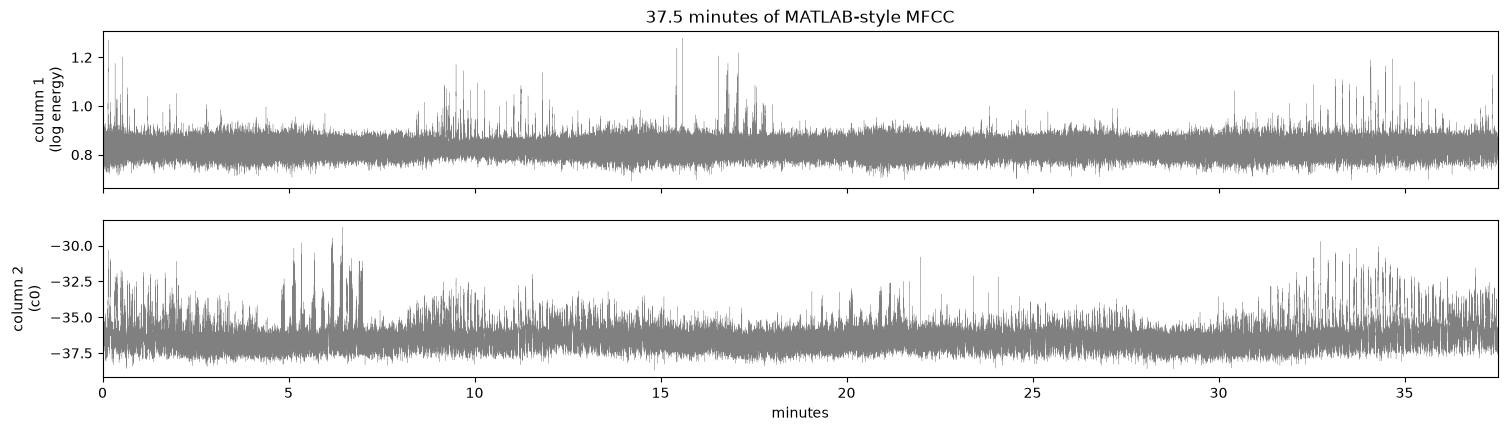

In [3]:
coeffs, FR = w.load_or_compute_mfcc()
T = coeffs[:, COEF_COLUMN - 1].astype(np.float64)
n_expected = (450_000_000 - 6000) // 2000 + 1
print(f"MFCC matrix: {coeffs.shape} (expected {n_expected:,} frames), {FR:.0f} frames/s")
print(f"band edges: {w.matlab_band_edges()[0]:.2f} Hz ... {w.matlab_band_edges()[-1]:.1f} Hz")

t_min = np.arange(len(T)) / FR / 60
fig, axs = plt.subplots(2, 1, figsize=(18, 4.5), sharex=True)
axs[0].plot(t_min, coeffs[:, 0], color="gray", lw=0.2)
axs[0].set_ylabel("column 1\n(log energy)")
axs[1].plot(t_min, T, color="gray", lw=0.2)
axs[1].set_ylabel("column 2\n(c0)")
axs[1].set_xlabel("minutes")
axs[1].set_xlim(0, t_min[-1])
axs[0].set_title(f"{t_min[-1]:.1f} minutes of MATLAB-style MFCC")
plt.show()

## 2. Pilot: exclusion zone and motif strength

Two choices are not fixed by the figure, so a coarse pan matrix profile (2.5 s steps, 30 window sizes)
was computed for an exclusion zone of `m/2` (the value used in the Matrix Profile XX paper) and `m/1`
(the two occurrences of a motif may not overlap at all). Each was scored two ways:

* `pearson`: the Pearson correlation `1 - d^2 / (2m)` of the motif pair
* `weighted`: `sqrt(m / max_m) * (1 - d / (2 sqrt(m)))`, the distance margin below its maximum
  `2 sqrt(m)`. It rewards longer repeats, which is what makes the ridges in the original 3D figure rise
  towards 100 s.

The pilot caches are produced by `python whale_mfcc.py --step 250 --excl-denom 2` (and `1`).

In [4]:
def describe(motifs, label=""):
    for rank, mo in enumerate(motifs, 1):
        a, b = sorted((mo["i"], mo["j"]))
        rho = 1 - mo["d"] ** 2 / (2 * mo["m"])
        print(
            f"{label}top {rank}: {mo['m'] / FR:6.1f} s at {a / FR / 60:6.2f} and "
            f"{b / FR / 60:6.2f} min, correlation {rho:.3f}"
        )


for denom in (2, 1):
    path = f"whale_pan_mp_matlab_step250_excl{denom}.npz"
    if not os.path.exists(path):
        print(f"{path} not found, skipping")
        continue
    pilot = np.load(path)
    pilot_ms = np.sort(pilot["M"])
    for score in ("pearson", "weighted"):
        S_pilot = w.motif_strength(pilot["PAN"], pilot_ms, score=score)
        print(f"exclusion zone m/{denom}, score={score}")
        describe(w.top_pan_motifs(S_pilot, pilot_ms, T, k=3, excl_denom=denom), "    ")

exclusion zone m/2, score=pearson


    top 1:   27.5 s at  33.77 and  34.36 min, correlation 0.881
    top 2:   27.5 s at  34.36 and  35.13 min, correlation 0.873
    top 3:   27.5 s at  34.41 and  35.76 min, correlation 0.853
exclusion zone m/2, score=weighted


    top 1:  100.0 s at  33.47 and  34.44 min, correlation 0.762
    top 2:  100.0 s at  10.30 and  32.76 min, correlation 0.662
    top 3:   65.0 s at   9.21 and  33.22 min, correlation 0.693
exclusion zone m/1, score=pearson


    top 1:   27.5 s at  33.77 and  34.36 min, correlation 0.881
    top 2:   27.5 s at  34.36 and  35.13 min, correlation 0.873
    top 3:   27.5 s at  34.41 and  35.76 min, correlation 0.853
exclusion zone m/1, score=weighted


    top 1:  100.0 s at  32.68 and  34.61 min, correlation 0.685
    top 2:  100.0 s at  10.30 and  32.76 min, correlation 0.662
    top 3:   65.0 s at   9.21 and  33.22 min, correlation 0.693


The Pearson score always prefers the shortest window (a 27.5 s phrase repeated back-to-back), so it
cannot produce the long, rising ridges of the original figure. The weighted score does, and it finds
the **10.3 min / 32.8 min** pair of the original figure. We therefore continue with `SCORE="weighted"`
and `EXCL_DENOM=1`.

## 3. Full pan matrix profile (0.5 s steps)

In [5]:
min_m = int(round(MIN_SEC * FR))
max_m = int(round(MAX_SEC * FR))
pmp = w.compute_pan_mp(T, min_m, max_m, STEP, PAN_CACHE, excl_denom=EXCL_DENOM)
PAN = pmp._PAN  # raw distances, rows in ascending window size order
ms = np.sort(pmp.M_)
m_sec = ms / FR
print(f"{len(ms)} window sizes from {m_sec[0]} s to {m_sec[-1]} s")

Resumed 146/146 window sizes from cache
146 window sizes from 27.5 s to 100.0 s


## 4. Motif strength surface

Anything weaker than `FLOOR` is flattened onto the dark blue base so that only the motif ridges stand out.

floor = 0.342, max strength = 0.604


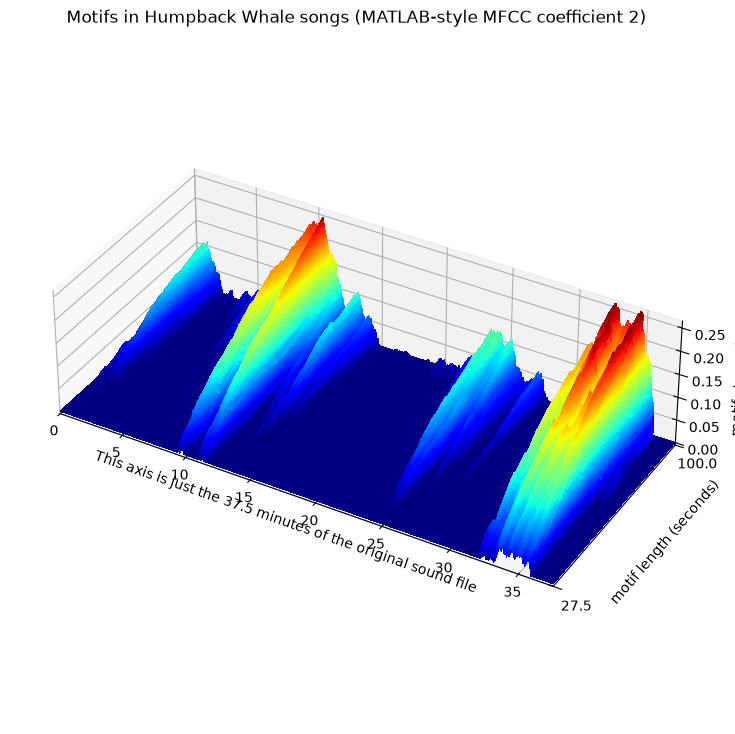

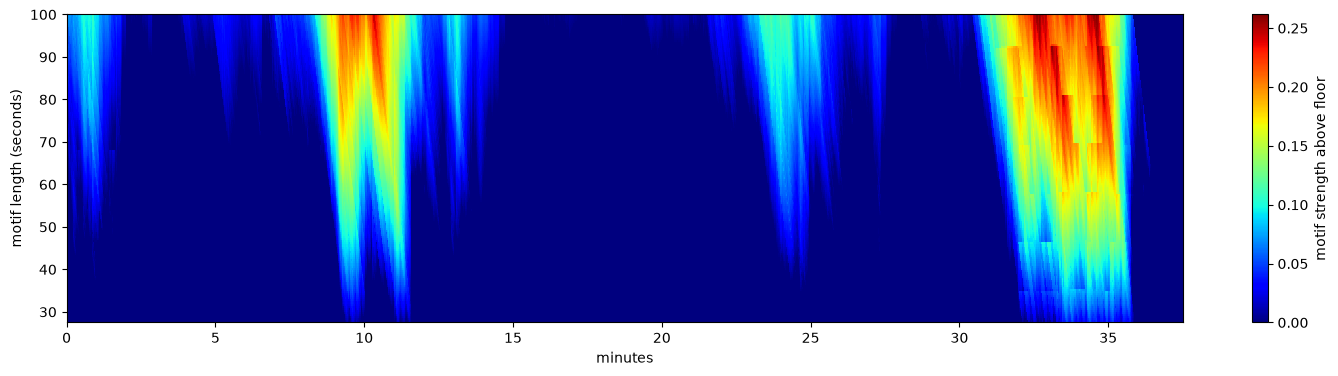

In [6]:
S = w.motif_strength(PAN, ms, score=SCORE, max_m=max_m)
valid = np.isfinite(S)
FLOOR = np.percentile(S[valid], 60)
surface = np.where(valid, np.clip(S - FLOOR, 0.0, None), 0.0)
print(f"floor = {FLOOR:.3f}, max strength = {S[valid].max():.3f}")


def plot_surface(surface, t_min, m_sec, time_decimation=100, elev=35, azim=-60):
    Z = surface[:, ::time_decimation]
    X, Y = np.meshgrid(t_min[::time_decimation], m_sec)
    fig = plt.figure(figsize=(16, 9))
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(
        X, Y, Z, cmap=cm.jet, rcount=Z.shape[0], ccount=Z.shape[1], linewidth=0, antialiased=False
    )
    ax.set_xlabel("This axis is just the 37.5 minutes of the original sound file")
    ax.set_ylabel("motif length (seconds)")
    ax.set_zlabel("motif strength")
    ax.set_xlim(t_min[0], t_min[-1])
    ax.set_ylim(m_sec[0], m_sec[-1])
    ax.set_yticks([m_sec[0], m_sec[-1]])
    ax.set_box_aspect((3, 1.4, 0.8), zoom=0.9)
    ax.view_init(elev=elev, azim=azim)
    return ax


plot_surface(surface, t_min, m_sec)
plt.title("Motifs in Humpback Whale songs (MATLAB-style MFCC coefficient 2)")
plt.show()

fig, ax = plt.subplots(figsize=(18, 4))
im = ax.imshow(
    surface,
    aspect="auto",
    origin="lower",
    cmap=cm.jet,
    extent=(t_min[0], t_min[-1], m_sec[0], m_sec[-1]),
    interpolation="nearest",
)
ax.set_xlabel("minutes")
ax.set_ylabel("motif length (seconds)")
fig.colorbar(im, ax=ax, label="motif strength above floor")
plt.show()

## 5. Top motifs, refined to 0.1 s

`w.top_pan_motifs` takes the strongest point of the surface, finds its nearest neighbor (with the same
exclusion zone), masks both occurrences for every length, and repeats. `w.refine_motifs` then computes
exact matrix profiles every 0.1 s within +/- 2 s of each motif's length (limited to 27.5 - 100 s) and keeps
the strongest subsequence within +/- 10 s of the original occurrence. Note that a later motif may reuse an
occurrence of an earlier one as its nearest neighbor: the same song section can be sung three times.

In [7]:
coarse = w.top_pan_motifs(S, ms, T, k=3, excl_denom=EXCL_DENOM)
describe(coarse, "coarse  ")
motifs = w.refine_motifs(
    coarse,
    T,
    delta=200,
    fine_step=10,
    window=1000,
    score=SCORE,
    max_m=max_m,
    min_m=min_m,
    excl_denom=EXCL_DENOM,
    cache_path=REFINE_CACHE,
    verbose=False,
)
describe(motifs, "refined ")

coarse  top 1:   99.5 s at  32.68 and  34.61 min, correlation 0.689
coarse  top 2:  100.0 s at  10.30 and  32.76 min, correlation 0.662
coarse  top 3:   65.5 s at   9.20 and  33.22 min, correlation 0.690


refined top 1:   99.7 s at  32.68 and  34.61 min, correlation 0.689
refined top 2:  100.0 s at  10.30 and  32.76 min, correlation 0.662
refined top 3:   67.5 s at   9.27 and  33.28 min, correlation 0.712


## 6. The original top-1 pair: 10.4 min vs 32.8 min, at every length

The original figure highlights the top-1 motif at **10.4 min** (blue) and **32.8 min** (red). To check
this pair directly, we AB-join the region 9.4 - 11.4 min against 31.8 - 33.8 min for every motif length and
record the best matching pair and its correlation.

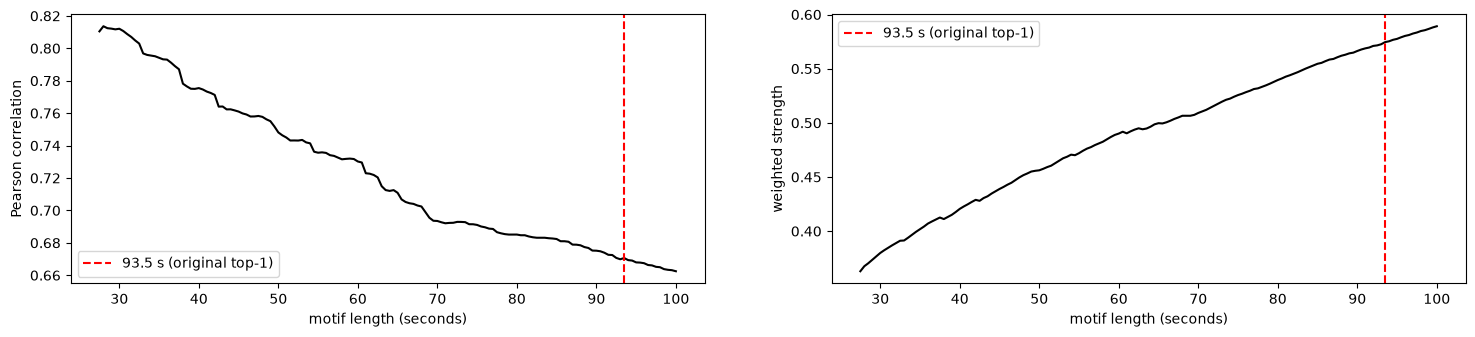

at 93.5 s the best pair starts at 10.40 and 32.87 min (correlation 0.671)


In [8]:
span = int(2 * 60 * FR)
profile = w.pair_length_profile(
    T, int(9.4 * 60 * FR), int(31.8 * 60 * FR), span, ms, cache_path=PAIR_CACHE
)
rho = 1 - profile["d"] ** 2 / (2 * profile["m"])
weighted = w.motif_strength(profile["d"][:, None], profile["m"], "weighted", max_m=max_m)[:, 0]

fig, axs = plt.subplots(1, 2, figsize=(18, 3.5))
axs[0].plot(m_sec, rho, color="k")
axs[0].set_ylabel("Pearson correlation")
axs[1].plot(m_sec, weighted, color="k")
axs[1].set_ylabel("weighted strength")
for ax in axs:
    ax.axvline(REF_TOP1_SEC, color="r", ls="--", label=f"{REF_TOP1_SEC} s (original top-1)")
    ax.set_xlabel("motif length (seconds)")
    ax.legend()
plt.show()

r = int(np.argmin(np.abs(m_sec - REF_TOP1_SEC)))
ref_pair = {k: int(profile[k][r]) for k in ("m", "i", "j")} | {"d": float(profile["d"][r])}
print(
    f"at {m_sec[r]} s the best pair starts at {profile['i'][r] / FR / 60:.2f} and "
    f"{profile['j'][r] / FR / 60:.2f} min (correlation {rho[r]:.3f})"
)

## 7. Figures in the style of the original

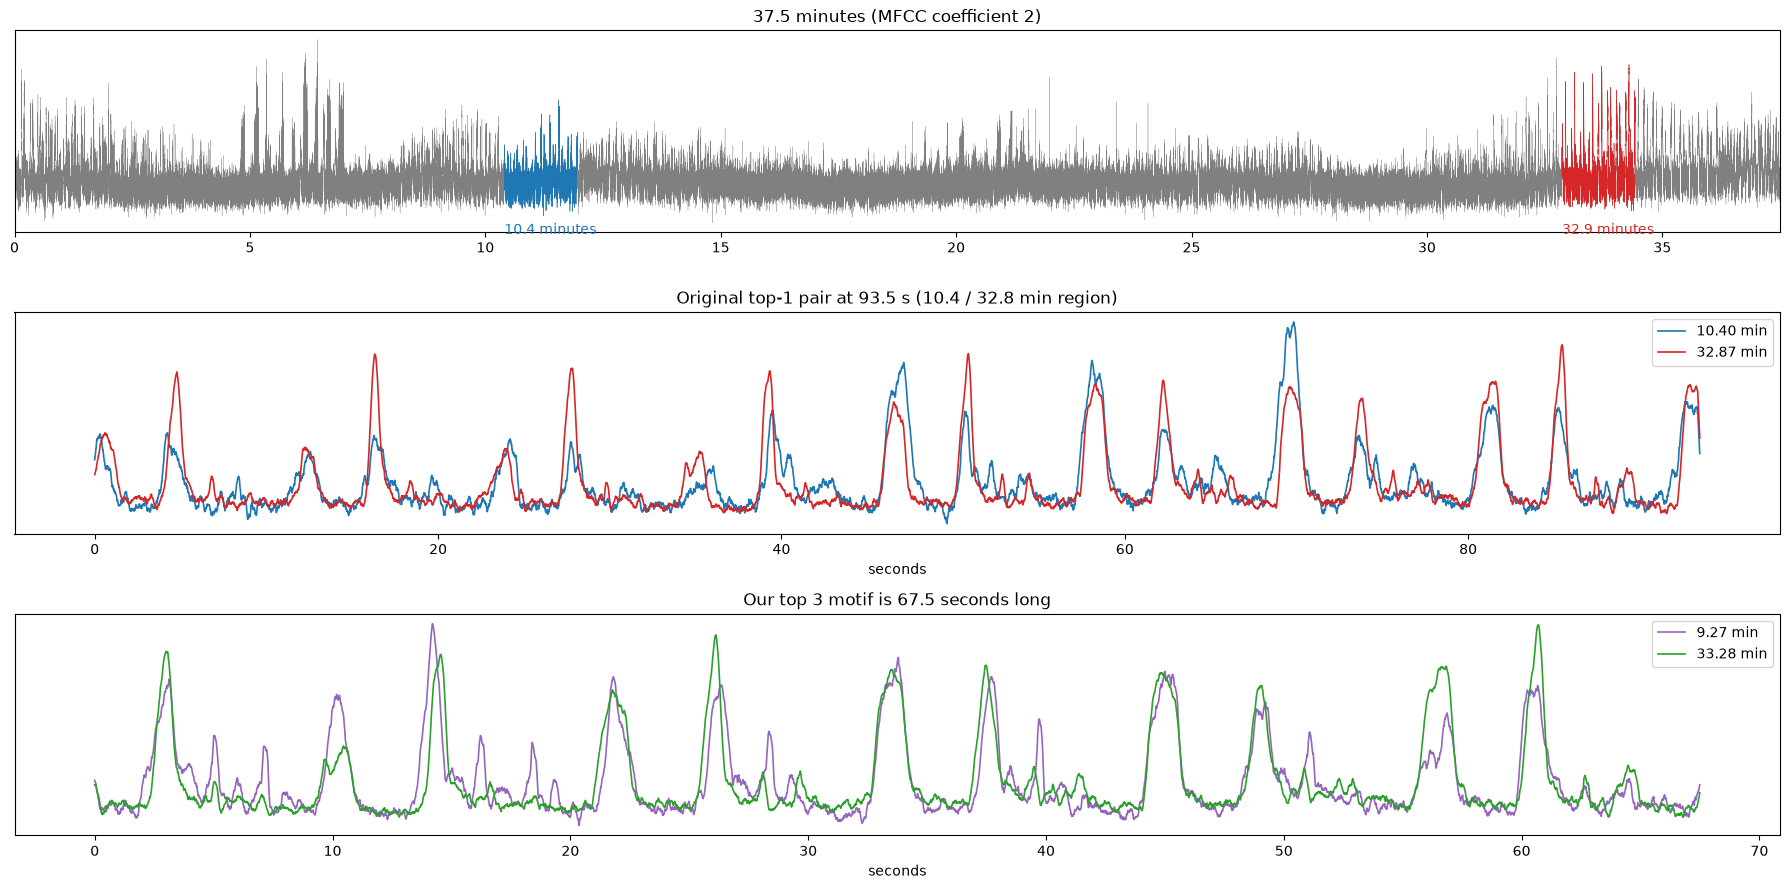

In [9]:
def znorm(x):
    return (x - x.mean()) / x.std()


def smooth(x, n=25):
    return np.convolve(x, np.ones(n) / n, mode="same") if n > 1 else x


def overlay(ax, mo, colors, title, smooth_frames=25):
    m = mo["m"]
    secs = np.arange(m) / FR
    for start, c in zip(sorted((mo["i"], mo["j"])), colors):
        seg = smooth(znorm(T[start : start + m]), smooth_frames)
        ax.plot(secs, seg, color=c, lw=1.2, label=f"{start / FR / 60:.2f} min")
    ax.set_title(title)
    ax.set_xlabel("seconds")
    ax.set_yticks([])
    ax.legend(loc="upper right")


def author_figure(top1, top3, top1_label, top3_label):
    fig = plt.figure(figsize=(18, 9))
    gs = fig.add_gridspec(3, 1, height_ratios=[1, 1.1, 1.1])
    ax0 = fig.add_subplot(gs[0])
    ax0.plot(t_min, T, color="gray", lw=0.2)
    a, b = sorted((top1["i"], top1["j"]))
    for start, c in ((a, "tab:blue"), (b, "tab:red")):
        sl = slice(start, start + top1["m"])
        ax0.plot(t_min[sl], T[sl], color=c, lw=0.3)
        ax0.text(t_min[start], T.min(), f"{start / FR / 60:.1f} minutes", color=c, va="top")
    ax0.set_xlim(0, t_min[-1])
    ax0.set_title(f"{t_min[-1]:.1f} minutes (MFCC coefficient {COEF_COLUMN})")
    ax0.set_yticks([])
    overlay(fig.add_subplot(gs[1]), top1, ("tab:blue", "tab:red"), top1_label)
    overlay(fig.add_subplot(gs[2]), top3, ("tab:purple", "tab:green"), top3_label)
    plt.tight_layout()
    plt.show()


author_figure(
    ref_pair,
    motifs[2],
    f"Original top-1 pair at {ref_pair['m'] / FR:.1f} s (10.4 / 32.8 min region)",
    f"Our top 3 motif is {motifs[2]['m'] / FR:.1f} seconds long",
)

The overlays are z-normalized and lightly smoothed (0.25 s moving average) for display only; all distances
are computed on the raw 10 ms series. Our own ranking, shown the same way:

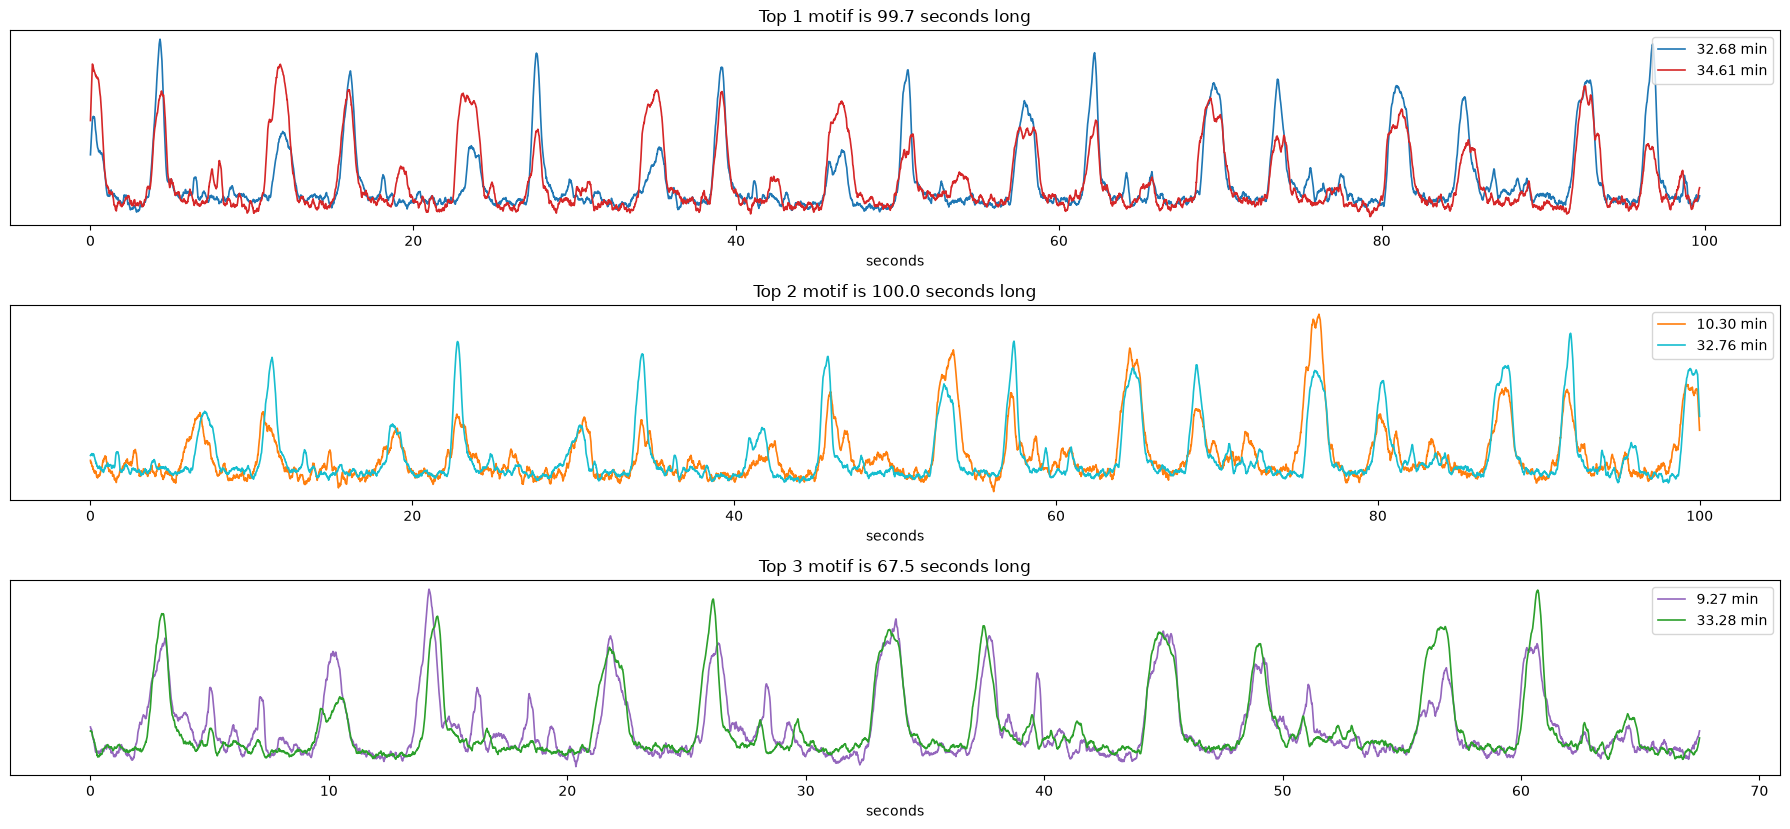

In [10]:
fig, axs = plt.subplots(len(motifs), 1, figsize=(18, 2.8 * len(motifs)))
palette = [("tab:blue", "tab:red"), ("tab:orange", "tab:cyan"), ("tab:purple", "tab:green")]
for rank, (ax, mo, colors) in enumerate(zip(axs, motifs, palette), 1):
    overlay(ax, mo, colors, f"Top {rank} motif is {mo['m'] / FR:.1f} seconds long")
plt.tight_layout()
plt.show()

## 8. Validation against the original figure

In [11]:
def find_pair(motifs, near_a, near_b, tol_min=1.0):
    for rank, mo in enumerate(motifs, 1):
        a, b = sorted((mo["i"] / FR / 60, mo["j"] / FR / 60))
        if abs(a - near_a) <= tol_min and abs(b - near_b) <= tol_min:
            return rank, mo
    return None, None


def corr(mo):
    return 1 - mo["d"] ** 2 / (2 * mo["m"])


rank, mo = find_pair(motifs, *REF_TOP1_MIN)
print(f"Original top 1: {REF_TOP1_SEC} s at {REF_TOP1_MIN[0]} / {REF_TOP1_MIN[1]} min")
if mo is None:
    print("  not among our top 3 motifs")
else:
    a, b = sorted((mo["i"], mo["j"]))
    print(
        f"  ours: rank {rank}, {mo['m'] / FR:.1f} s at {a / FR / 60:.2f} / {b / FR / 60:.2f} min, "
        f"correlation {corr(mo):.3f}"
    )
print(
    f"  ours at exactly {ref_pair['m'] / FR:.1f} s: {ref_pair['i'] / FR / 60:.2f} / "
    f"{ref_pair['j'] / FR / 60:.2f} min, correlation {corr(ref_pair):.3f}"
)

mo3 = motifs[2]
a, b = sorted((mo3["i"], mo3["j"]))
print(f"Original top 3: {REF_TOP3_SEC} s")
print(
    f"  ours: {mo3['m'] / FR:.1f} s at {a / FR / 60:.2f} / {b / FR / 60:.2f} min, "
    f"correlation {corr(mo3):.3f}"
)

for label, center in [("10.4 min", 10.4), ("32.8 min", 32.8)]:
    c = int(center * 60 * FR)
    win = S[:, max(0, c - 6000) : c + 6000]
    r, k = np.unravel_index(np.argmax(win), win.shape)
    print(f"strongest ridge within 1 min of {label}: {m_sec[r]:.1f} s long, strength {win[r, k]:.3f}")

Original top 1: 93.5 s at 10.4 / 32.8 min
  ours: rank 2, 100.0 s at 10.30 / 32.76 min, correlation 0.662
  ours at exactly 93.5 s: 10.40 / 32.87 min, correlation 0.671
Original top 3: 82.1 s
  ours: 67.5 s at 9.27 / 33.28 min, correlation 0.712
strongest ridge within 1 min of 10.4 min: 100.0 s long, strength 0.589
strongest ridge within 1 min of 32.8 min: 99.5 s long, strength 0.604


## Findings

* **MFCC**: the MATLAB-default MFCC gives exactly 224,998 frames (10 ms), and column 2 (c0) has the same
  spiky shape as the strip in the original figure.
* **Surface**: with the length-weighted strength, the pan matrix profile has the same structure as the
  original 3D figure - ridges that rise towards 100 s, with the two dominant ones around 9-11 min and
  32-35 min.
* **Top-1 pair**: at exactly 93.5 s, the best match between the 10.4 min and 32.8 min regions starts at
  **10.40 min and 32.87 min** - the positions reported in the original figure - and the overlay shows the
  same peak-for-peak alignment. In our ranking this pair is **#2** (100 s at 10.30 / 32.76 min); #1 is a
  late-song pair (32.68 / 34.61 min) whose strength is only slightly higher (0.604 vs 0.589).
* **Length**: neither the Pearson nor the weighted score has a maximum at 93.5 s for this pair (Pearson
  slowly decreases with length, the weighted score slowly increases up to the 100 s limit), so the exact
  93.5 s and 82.1 s cut-offs depend on a ranking rule the figure does not specify. Our top-3 motif is
  67.5 s (9.27 / 33.28 min), not 82.1 s.